# Compensation associations

Use source units, exploratory tests and adjustment; no discrimination claim.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))


In [2]:
import json, pandas as pd
from IPython.display import display, Image
results=json.loads((ROOT/'reports/results.json').read_text())

In [3]:
from src.data_cleaning import load_hr
from src.statistics import compensation_tests
hr=load_hr(ROOT/'data/raw/emp_attrition.csv')
display(hr.groupby(['Department','Gender']).MonthlyIncome.agg(['count','mean','median','std']))

count         mean  median          std
Department             Gender                                         
Human Resources        Female     20  7264.000000  4313.5  6143.404756
                       Male       43  6371.023256  3886.0  5668.652996
Research & Development Female    379  6513.691293  4615.0  4808.354321
                       Male      582  6129.888316  4174.5  4950.209893
Sales                  Female    189  6972.126984  5666.0  4285.461006
                       Male      257  6949.645914  6134.0  3892.068876

female_n                                                                                        588
male_n                                                                                          882
female_mean                                                                             6686.566327
male_mean                                                                               6380.507937
mean_difference_female_minus_male                                                         306.05839
cohens_d                                                                                    0.06502
welch_p                                                                                    0.221837
mann_whitney_p                                                                             0.088417
rank_biserial_female_minus_male                                                            0.052391
adjusted_log_income_male_vs_female_coefficient                                             0.009564


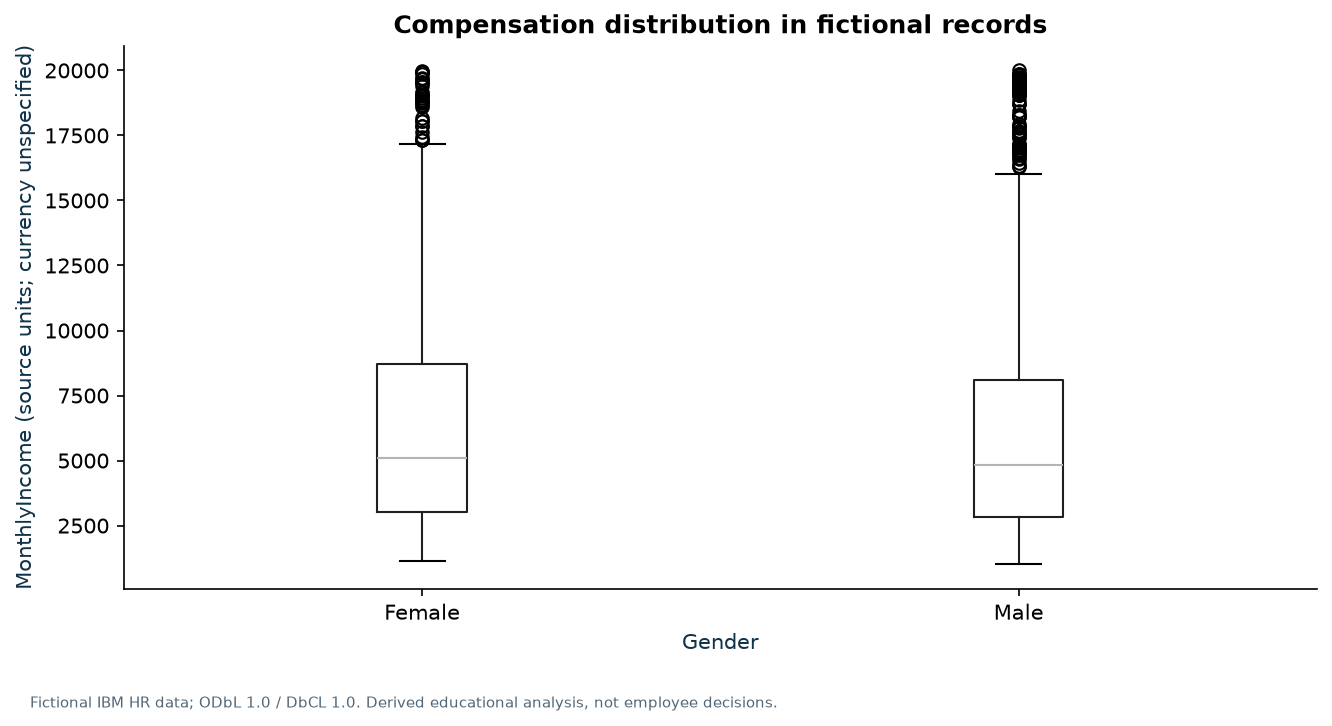

Role adjustment does not remove unmeasured confounding; synthetic effects are not real compensation evidence.


In [4]:
display(pd.Series(compensation_tests(hr)))
display(Image(filename=str(ROOT/'figures/compensation.png')))
print('Role adjustment does not remove unmeasured confounding; synthetic effects are not real compensation evidence.')